# Can TSA checkpoint traffic track Delta's revenue?

## 1. Question and data sources

The TSA publishes how many people pass through U.S. airport security checkpoints every day, with only a few days' delay. Delta reports its revenue once a quarter. This notebook tests whether the TSA counts can be used to track Delta's revenue before Delta reports it.

| File in `data/` | What it holds | Source | Script |
|---|---|---|---|
| `tsa_daily.csv` | Travelers screened per day, from January 2022 | TSA checkpoint travel numbers | `download_tsa.py` |
| `delta_ops.csv` | Adjusted revenue, passenger miles, seat miles, yield, fuel price, and the date each was filed | Delta's quarterly earnings press releases (SEC 8-K filings) | `download_delta_ops.py` |
| `delta_quarterly_revenue.csv` | GAAP revenue, which includes the refinery's outside sales | SEC EDGAR company facts | `download_delta_revenue.py` |
| `airfare_cpi_monthly.csv` | Consumer Price Index for airline fares, monthly | Bureau of Labor Statistics, series CUUR0000SETG01 | `download_airfare_cpi.py` |
| `airfare_cpi_quarterly.csv` | The same index averaged over each whole quarter | Same | Same |

The scripts fetch the data; this notebook only reads the files they saved.

### Key terms

- **GAAP revenue** is Delta's total operating revenue as reported under standard accounting rules. Besides tickets, cargo and the loyalty program, it includes fuel that Delta's own oil refinery sells to outside customers.
- **Adjusted revenue** is GAAP revenue minus those outside refinery sales. It is Delta's own measure, shown in a reconciliation table in each earnings release, and it is the revenue figure used throughout this analysis. Refinery sales have nothing to do with how many people fly and swing with fuel prices: they ranged from $0.6 billion to $2.6 billion a quarter over this period. In every quarter here, the refinery was the only difference between the two figures.
- **Passenger miles** (revenue passenger miles, RPMs) count one paying passenger flown one mile. They measure how much people actually flew on Delta.
- **Seat miles** (available seat miles, ASMs) count one seat flown one mile, filled or not. They measure how much capacity Delta offered.
- **Yield** (passenger mile yield) is passenger ticket revenue divided by passenger miles: the average price paid to fly one passenger one mile, in cents. Delta prints it in each earnings release.

## 2. Load the data

In [1]:
import pandas as pd


def by_quarter(frame):
    """Index a table by its quarter column, so tables can be lined up quarter by quarter."""
    return frame.set_index(pd.PeriodIndex(frame["quarter"], freq="Q", name="quarter"))


tsa_daily = pd.read_csv("data/tsa_daily.csv", parse_dates=["date"])
ops = by_quarter(pd.read_csv("data/delta_ops.csv"))
gaap = by_quarter(pd.read_csv("data/delta_quarterly_revenue.csv"))
airfare_monthly = pd.read_csv("data/airfare_cpi_monthly.csv")
airfare_quarterly = by_quarter(pd.read_csv("data/airfare_cpi_quarterly.csv"))

for name, frame in [
    ("TSA daily counts", tsa_daily),
    ("Delta adjusted revenue and operating stats", ops),
    ("Delta GAAP revenue", gaap),
    ("Airfare index, monthly", airfare_monthly),
    ("Airfare index, quarterly", airfare_quarterly),
]:
    print(f"{name}: {len(frame):,} rows")

TSA daily counts: 1,742 rows
Delta adjusted revenue and operating stats: 19 rows
Delta GAAP revenue: 19 rows
Airfare index, monthly: 56 rows
Airfare index, quarterly: 19 rows


## 3. Line up the quarters

Delta reports by calendar quarter, so everything else has to be put on the same footing.

### TSA travelers per quarter

The daily counts are summed into calendar quarters. Two details matter when doing that.

**Unfinished quarters are dropped.** A quarter is kept only if every one of its days is in the file. When this was written, the file held just the first 8 days of Q4 2026. Summed as if it were a whole quarter, that would look like travel had fallen about 90% from a year earlier, when really the quarter had barely begun.

**The leap day.** 2024 was a leap year, so Q1 2024 had 91 days where Q1 2023 and Q1 2025 had 90. One extra day is about 1% more travelers. So Q1 2024's growth looks about one point better than it really was, and Q1 2025's about one point worse. Delta's revenue and passenger miles gained the same extra day, so the comparison between TSA and Delta is not distorted, only the individual growth figures.

In [2]:
tsa_daily["quarter"] = tsa_daily["date"].dt.to_period("Q")
tsa = tsa_daily.groupby("quarter")["travelers"].agg(tsa_travelers="sum", days="count")

# Keep a quarter only if every one of its days is in the file.
days_in_quarter = (tsa.index.end_time.normalize() - tsa.index.start_time).days + 1
is_complete = tsa["days"] == days_in_quarter
for quarter in tsa.index[~is_complete]:
    print(f"Dropped {quarter}: only {tsa.loc[quarter, 'days']} days so far")
tsa = tsa[is_complete]

tsa.tail(4)

Dropped 2026Q4: only 8 days so far


,tsa_travelers,days
quarter,,
2025Q4,228297338,92
2026Q1,208660296,90
2026Q2,233763292,91
2026Q3,230749661,92


### Airfares: two versions for two jobs

The airfare index is monthly, so it has to be turned into one figure per quarter. This notebook does that two ways.

- **Three-month average**, the whole quarter. Used for the comparison charts and for explaining the mismatches. Those look back at what happened, so they should use the most complete data.
- **Two-month average**, the first two months of the quarter. Used only for the nowcast, for the reason below.

In both versions, growth compares the months with the same months a year earlier, and only months published in both years are counted.

#### The two-month rule

**The goal.** The nowcast predicts Delta's revenue before Delta announces it. So it can only use data that was already public before the announcement.

**An example: the third quarter (July to September).** July's airfare figure comes out in mid-August. August's comes out in mid-September. September's comes out in mid-October. Delta reports in the second week of October: October 9 in both 2025 and 2026. So on the day before Delta reports, only July and August are available.

**The check.** This was tested against the actual dates for the 16 quarters from Q4 2022 to Q3 2026, using the BLS archive of CPI release dates and the `filed_date` column in `delta_ops.csv`. The third month's figure came out after Delta reported 7 times, on the same day 5 times, and one day earlier 4 times. It never arrived with useful lead time.

**Why the rule applies to every quarter, not just the latest.** This is about consistency, not fairness. Using the third month for past quarters would not be look-ahead bias, because that data is public now. But a model should learn from the same kind of input it will later predict with, and a two-month average is a slightly different number from a three-month average, as the comparison below shows.

**The exception.** The BLS never published a figure for October 2025, because of that year's government shutdown, and the gap is permanent. The two-month figure for Q4 2025 therefore rests on November alone, compared with November 2024.

In [3]:
airfare_monthly["month"] = pd.PeriodIndex(airfare_monthly["month"], freq="M")
cpi = airfare_monthly.set_index("month")["airfare_cpi"]

# The quarterly file should be nothing more than the monthly file averaged by quarter.
assert cpi.groupby(cpi.index.asfreq("Q")).mean().round(3).equals(airfare_quarterly["airfare_cpi"]), "airfare files disagree"


def airfare_growth(quarter, months):
    """Year-over-year airfare growth, in percent, over the first `months` months of a quarter.

    Also returns how many months the figure rests on. Only months published in
    both years are counted, so the comparison is always like for like.
    """
    window = pd.period_range(quarter.asfreq("M", how="start"), periods=months, freq="M")
    this_year = cpi.reindex(window).to_numpy()
    last_year = cpi.reindex(window - 12).to_numpy()
    in_both = ~pd.isna(this_year) & ~pd.isna(last_year)
    if not in_both.any():
        return float("nan"), 0
    return (this_year[in_both].mean() / last_year[in_both].mean() - 1) * 100, int(in_both.sum())


rows = []
for quarter in tsa.index:
    growth_3mo, months_3mo = airfare_growth(quarter, 3)
    growth_2mo, months_2mo = airfare_growth(quarter, 2)
    rows.append(
        {
            "quarter": quarter,
            "airfare_index": airfare_quarterly.loc[quarter, "airfare_cpi"],
            "airfare_yoy_pct": growth_3mo,
            "airfare_months": months_3mo,
            "airfare_2mo_yoy_pct": growth_2mo,
            "airfare_2mo_months": months_2mo,
        }
    )
airfare = pd.DataFrame(rows).set_index("quarter").loc["2023Q1":]

for quarter, row in airfare.iterrows():
    if row["airfare_months"] < 3 or row["airfare_2mo_months"] < 2:
        print(
            f"{quarter}: three-month figure rests on {row['airfare_months']:.0f} of 3 months, "
            f"two-month figure on {row['airfare_2mo_months']:.0f} of 2"
        )

2025Q4: three-month figure rests on 2 of 3 months, two-month figure on 1 of 2
2026Q3: three-month figure rests on 2 of 3 months, two-month figure on 2 of 2


Two quarters are short of months. **Q4 2025** has no October in either version. **Q3 2026** has no September yet in the three-month version, because the BLS has not published it; until it does, the two versions are the same for that quarter.

#### How closely do the two versions match?

In [4]:
versions = airfare[["airfare_yoy_pct", "airfare_2mo_yoy_pct"]].copy()
versions["gap_points"] = versions["airfare_2mo_yoy_pct"] - versions["airfare_yoy_pct"]

# Judge the match only where the three-month figure really has three months.
full = versions[airfare["airfare_months"] == 3]
gap = full["gap_points"].abs()
print(f"Quarters compared: {len(full)}")
print(f"Same direction in every quarter: {(full['airfare_yoy_pct'] * full['airfare_2mo_yoy_pct'] > 0).all()}")
print(f"Correlation: {full['airfare_yoy_pct'].corr(full['airfare_2mo_yoy_pct']):.2f}")
print(f"Average gap: {gap.mean():.1f} points | largest: {gap.max():.1f} points ({gap.idxmax()})")
print(f"More than 2 points apart: {', '.join(gap[gap > 2].index.astype(str))}")
print(f"Typical size of the growth itself: {full['airfare_yoy_pct'].abs().mean():.0f} points")

versions.round(1)

Quarters compared: 13
Same direction in every quarter: True
Correlation: 0.99
Average gap: 1.6 points | largest: 3.9 points (2023Q2)
More than 2 points apart: 2023Q1, 2023Q2, 2025Q1, 2026Q1
Typical size of the growth itself: 9 points


,airfare_yoy_pct,airfare_2mo_yoy_pct,gap_points
quarter,,,
2023Q1,23.1,26.1,3.0
2023Q2,-11.5,-7.6,3.9
2023Q3,-15.2,-16.1,-0.9
2023Q4,-11.6,-12.7,-1.0
2024Q1,-6.6,-6.3,0.3
2024Q2,-5.6,-5.8,-0.2
2024Q3,-0.9,-2.1,-1.2
2024Q4,5.5,4.4,-1.1
2025Q1,0.3,3.1,2.8


**Closely, but not identically.** The two versions point the same direction in every quarter and move together almost perfectly (correlation 0.99). Over the 13 quarters where all three months exist, they differ by about 1.6 percentage points on average and by 3 to 4 points in four quarters, against growth that is typically around 9 points. So the choice does not change the story, but it is not immaterial. The clearest case is Q1 2026: the two-month figure shows fares up 4.6% and the three-month figure 7.9%, because fares rose sharply in March.

### One table

Everything is merged on the quarter. Year-over-year growth compares each quarter with the same quarter a year earlier, which cancels out the seasons: summer is always busier than winter, for travel and for revenue alike.

In [5]:
table = tsa[["tsa_travelers"]].join(
    [
        ops[["adjusted_revenue_usd", "rpm_millions", "asm_millions", "passenger_mile_yield_cents", "fuel_price_per_gallon_usd"]],
        gaap["revenue_usd"].rename("gaap_revenue_usd"),
        airfare_quarterly["airfare_cpi"].rename("airfare_index"),
    ],
    how="inner",
)

# Stop here if a quarter is skipped or a value is missing, rather than chart a broken table.
assert list(table.index) == list(pd.period_range(table.index[0], table.index[-1], freq="Q")), "quarters are not consecutive"
assert table.notna().all().all(), "a value is missing"

growth_names = {
    "tsa_travelers": "tsa_yoy_pct",
    "adjusted_revenue_usd": "adj_revenue_yoy_pct",
    "gaap_revenue_usd": "gaap_revenue_yoy_pct",
    "rpm_millions": "rpm_yoy_pct",
    "asm_millions": "asm_yoy_pct",
    "passenger_mile_yield_cents": "yield_yoy_pct",
}
for column, name in growth_names.items():
    # Four rows up is the same quarter one year earlier.
    table[name] = table[column].pct_change(4) * 100

# Airfare growth comes from the monthly figures above, in both versions.
table = table.join(airfare.drop(columns="airfare_index"))

print(f"{len(table)} quarters, {table.index[0]} to {table.index[-1]}")

19 quarters, 2022Q1 to 2026Q3


**The levels**, in readable units:

In [6]:
pd.DataFrame(
    {
        "TSA travelers (millions)": table["tsa_travelers"] / 1e6,
        "Adjusted revenue ($B)": table["adjusted_revenue_usd"] / 1e9,
        "GAAP revenue ($B)": table["gaap_revenue_usd"] / 1e9,
        "Passenger miles (billions)": table["rpm_millions"] / 1e3,
        "Seat miles (billions)": table["asm_millions"] / 1e3,
        "Yield (cents per mile)": table["passenger_mile_yield_cents"],
        "Fuel price ($ per gallon)": table["fuel_price_per_gallon_usd"],
        "Airfare index (3-month)": table["airfare_index"],
    }
).round(2)

,TSA travelers (millions),Adjusted revenue ($B),GAAP revenue ($B),Passenger miles (billions),Seat miles (billions),Yield (cents per mile),Fuel price ($ per gallon),Airfare index (3-month)
quarter,,,,,,,,
2022Q1,158.81,8.16,9.35,38.70,51.81,17.85,2.79,225.56
2022Q2,200.07,12.31,13.82,51.52,58.90,21.27,3.74,328.70
2022Q3,202.46,12.84,13.98,54.79,63.01,20.93,3.57,293.14
2022Q4,198.73,12.29,13.44,50.48,59.51,21.57,3.28,285.17
2023Q1,191.19,11.84,12.76,49.69,61.35,20.95,3.01,277.55
2023Q2,221.93,14.61,15.58,60.80,68.99,21.72,2.52,290.75
2023Q3,225.43,14.55,15.49,64.10,73.23,20.47,2.76,248.56
2023Q4,220.00,13.66,14.22,57.66,68.46,21.12,3.01,252.02
2024Q1,206.52,12.56,13.75,54.21,65.54,20.53,2.79,259.35


**Year-over-year growth**, in percent. Comparisons start in Q1 2023, because 2022 is the base year. Airfare growth here is the three-month version:

In [7]:
growth = table.loc["2023Q1":, list(growth_names.values()) + ["airfare_yoy_pct"]]
growth.round(1)

,tsa_yoy_pct,adj_revenue_yoy_pct,gaap_revenue_yoy_pct,rpm_yoy_pct,asm_yoy_pct,yield_yoy_pct,airfare_yoy_pct
quarter,,,,,,,
2023Q1,20.4,45.1,36.5,28.4,18.4,17.4,23.1
2023Q2,10.9,18.7,12.7,18.0,17.1,2.1,-11.5
2023Q3,11.3,13.3,10.8,17.0,16.2,-2.2,-15.2
2023Q4,10.7,11.1,5.9,14.2,15.1,-2.1,-11.6
2024Q1,8.0,6.1,7.8,9.1,6.8,-2.0,-6.6
2024Q2,6.7,5.4,6.9,7.3,8.2,-2.3,-5.6
2024Q3,4.3,0.3,1.2,3.5,4.0,-3.4,-0.9
2024Q4,2.5,5.7,9.4,4.7,5.2,0.5,5.5
2025Q1,-0.4,3.3,2.1,2.7,4.4,0.4,0.3


In [8]:
# Average growth per calendar year (2026 covers Q1 to Q3 only).
growth.groupby(growth.index.year).mean().round(1)

,tsa_yoy_pct,adj_revenue_yoy_pct,gaap_revenue_yoy_pct,rpm_yoy_pct,asm_yoy_pct,yield_yoy_pct,airfare_yoy_pct
quarter,,,,,,,
2023,13.3,22.1,16.5,19.4,16.7,3.8,-3.8
2024,5.4,4.4,6.3,6.1,6.1,-1.8,-1.9
2025,0.3,2.3,2.8,1.4,3.4,0.4,-2.0
2026,-0.7,13.0,17.6,0.9,0.9,10.6,19.0


**What the table shows.**

- **2023** was the tail of the recovery: everything grew fast. TSA travelers were up 13% on average and Delta's adjusted revenue 22%.
- **2024 and 2025** were steady. TSA growth and adjusted revenue growth were both in low single digits and close together (5.4% against 4.4% on average in 2024, 0.3% against 2.3% in 2025).
- **2026** is where they part. TSA travelers were roughly flat to down (-2.8% in Q3) and Delta's passenger miles grew about 1%, yet adjusted revenue rose 9% to 16%. The airfare index rose about 24% in Q2 and Q3.

**Mismatches to explain** (taken up in the "Explain the mismatches" section).

1. **2023: TSA understated Delta.** TSA travelers grew 13.3% on average, but Delta's passenger miles grew 19.4% and its adjusted revenue 22.1%. There are two possible explanations, and the data here cannot separate them.
   - *Longer trips.* International travel recovered strongly in 2023. Delta's Q2 2023 release reported international passenger revenue 61% higher than a year earlier. TSA counts each traveler once whatever the distance, so longer trips raise miles and revenue without raising the count.
   - *Delta growing faster than the industry.* Delta's seat miles grew 16.7% on average in 2023 as it restored capacity. If its share of travelers rose, a count of all airlines' travelers would understate its growth.
2. **2026: TSA missed the fare increase.** Traffic was flat, but revenue per mile rose. TSA measures how many people fly, not what they pay.

### Limitation: TSA counts every airline

TSA counts travelers on all airlines, not just Delta. Comparing TSA growth with Delta's growth therefore only works if Delta's share of travelers stays roughly stable. If Delta grows faster than the industry, TSA understates Delta's growth, and the reverse.

Delta's share cannot be measured from the sources used here. Delta does not publish quarterly passenger counts: none appear in its earnings releases (all 19 checked), its latest 10-Q, or its latest 10-K.

## 4. Compare and chart

Four charts, then a measure of how closely TSA traffic and revenue move together. All growth figures compare a quarter with the same quarter a year earlier. Airfare growth is the three-month version.

In [9]:
import matplotlib.pyplot as plt

# One fixed color per measure, so a measure looks the same in every chart it appears in.
COLORS = {
    "TSA travelers": "#2a78d6",
    "Adjusted revenue": "#eb6834",
    "Passenger miles": "#1baf7a",
    "GAAP revenue": "#4a3aa7",
    "Delta yield": "#e87ba4",
    "Airfare index": "#008300",
    "Fuel price": "#e34948",
}
SURFACE, INK, INK_SECONDARY, INK_MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"]})


def line_chart(data, title, subtitle, value_format="{:+.1f}%", tick_format="{:.0f}%", from_zero=False):
    """Draw one line per column of `data` (indexed by quarter), each labeled at its right-hand end."""
    fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=110, facecolor=SURFACE)
    fig.subplots_adjust(left=0.07, right=0.76, top=0.84, bottom=0.2)
    ax.set_facecolor(SURFACE)
    x = list(range(len(data)))

    for name in data.columns:
        ax.plot(x, data[name], color=COLORS[name], linewidth=2, solid_capstyle="round", solid_joinstyle="round", label=name)
        # A dot on the latest quarter, ringed in the background color, with its value written beside it.
        ax.plot(x[-1], data[name].iloc[-1], "o", color=COLORS[name], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(
            f"{name}  {value_format.format(data[name].iloc[-1])}",
            (x[-1], data[name].iloc[-1]),
            xytext=(10, 0),
            textcoords="offset points",
            va="center",
            fontsize=9.5,
            color=INK_SECONDARY,
        )

    # Quarters along the bottom, with the year written under each first quarter.
    ax.set_xticks(x)
    ax.set_xticklabels([f"Q{q.quarter}\n{q.year}" if q.quarter == 1 else f"Q{q.quarter}" for q in data.index])
    ax.tick_params(axis="both", length=0, labelsize=9, labelcolor=INK_MUTED)
    ax.yaxis.set_major_formatter(lambda value, _: tick_format.format(value))
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ax.spines.values():
        side.set_visible(False)
    if from_zero:
        ax.set_ylim(0, data.max().max() * 1.15)
    # A slightly stronger line marks zero growth (or the bottom of a chart that starts at zero).
    ax.axhline(0, color=AXIS, linewidth=1)

    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK, pad=26)
    ax.text(0, 1.04, subtitle, transform=ax.transAxes, fontsize=10, color=INK_SECONDARY)
    if len(data.columns) > 1:
        ax.legend(loc="upper left", bbox_to_anchor=(-0.01, -0.17), ncol=len(data.columns), frameon=False, fontsize=9.5, labelcolor=INK_SECONDARY)
    return ax

### Chart 1: TSA travelers, Delta's passenger miles and Delta's adjusted revenue

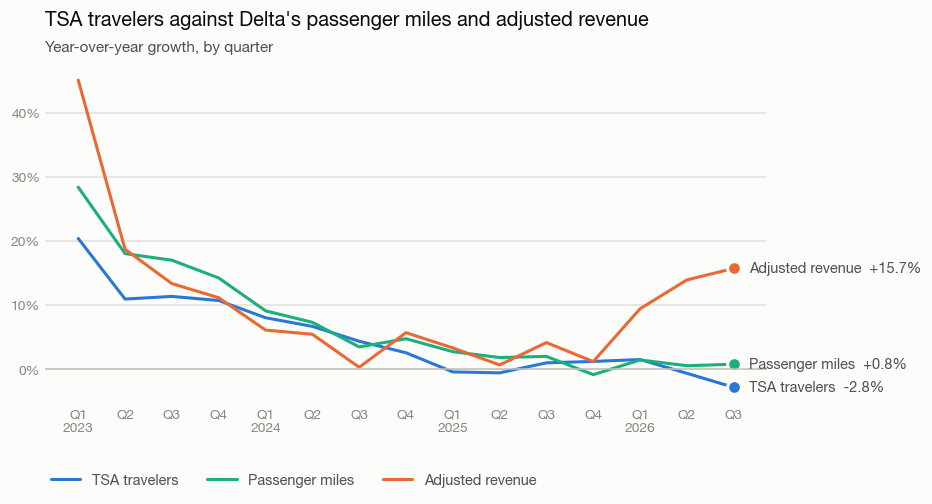

Correlation of TSA growth with Delta's passenger mile growth: 0.97


In [10]:
chart = table.loc["2023Q1":, ["tsa_yoy_pct", "rpm_yoy_pct", "adj_revenue_yoy_pct"]]
chart.columns = ["TSA travelers", "Passenger miles", "Adjusted revenue"]
line_chart(chart, "TSA travelers against Delta's passenger miles and adjusted revenue", "Year-over-year growth, by quarter")
plt.show()

print(f"Correlation of TSA growth with Delta's passenger mile growth: {chart['TSA travelers'].corr(chart['Passenger miles']):.2f}")

**What it shows.** TSA travelers and Delta's passenger miles move together the whole way (correlation 0.97). TSA is a good read on how much people fly Delta. Adjusted revenue follows both through 2024 and 2025, but sits well above them in early 2023 and pulls sharply away in 2026, when revenue grew 9% to 16% while traffic was flat. So when TSA and revenue part ways, the cause is not that TSA misread how much people flew.

### How closely does TSA growth track revenue growth?

In [11]:
compare = table.loc["2023Q1":, ["tsa_yoy_pct", "adj_revenue_yoy_pct"]].copy()
compare["gap_points"] = compare["adj_revenue_yoy_pct"] - compare["tsa_yoy_pct"]

# A quarter is flagged when the two growth rates are more than 5 points apart.
# The cut-off sits in a natural break: the smallest flagged gap is about 8, the largest unflagged about 4.
GAP_THRESHOLD = 5
compare["flagged"] = compare["gap_points"].abs() > GAP_THRESHOLD


def tsa_revenue_correlation(rows):
    return rows["tsa_yoy_pct"].corr(rows["adj_revenue_yoy_pct"])


before_2026 = compare[compare.index.year < 2026]
print(f"Correlation, all {len(compare)} quarters:              {tsa_revenue_correlation(compare):.2f}")
print(f"Correlation, excluding 2026 ({len(before_2026)} quarters):    {tsa_revenue_correlation(before_2026):.2f}")
print(f"Correlation, also excluding Q1 2023 ({len(before_2026) - 1} quarters): {tsa_revenue_correlation(before_2026.drop(pd.Period('2023Q1'))):.2f}")
print("Flagged quarters:", ", ".join(f"{q} ({gap:+.1f})" for q, gap in compare.loc[compare["flagged"], "gap_points"].items()))

compare.round(1)

Correlation, all 15 quarters:              0.70
Correlation, excluding 2026 (12 quarters):    0.89
Correlation, also excluding Q1 2023 (11 quarters): 0.83
Flagged quarters: 2023Q1 (+24.7), 2023Q2 (+7.8), 2026Q1 (+7.9), 2026Q2 (+14.6), 2026Q3 (+18.6)


,tsa_yoy_pct,adj_revenue_yoy_pct,gap_points,flagged
quarter,,,,
2023Q1,20.4,45.1,24.7,True
2023Q2,10.9,18.7,7.8,True
2023Q3,11.3,13.3,2.0,False
2023Q4,10.7,11.1,0.4,False
2024Q1,8.0,6.1,-1.9,False
2024Q2,6.7,5.4,-1.2,False
2024Q3,4.3,0.3,-4.1,False
2024Q4,2.5,5.7,3.1,False
2025Q1,-0.4,3.3,3.7,False


**What it shows.** Correlation runs from -1 to 1, and 1 means two things move in perfect step. Across all 15 quarters, TSA growth and adjusted revenue growth have a correlation of 0.70. Leaving out 2026, it is 0.89. So TSA growth was a good guide to revenue growth until 2026, and a poor one during it.

Two cautions. Twelve quarters is a small sample. And the 0.89 leans on the 2023 recovery, when both were growing fast: leaving out Q1 2023 as well gives 0.83.

**Flagged quarters.** Five quarters have revenue growth more than 5 points away from TSA growth: Q1 2023 (24.7 points), Q2 2023 (7.8), Q1 2026 (7.9), Q2 2026 (14.6) and Q3 2026 (18.6). In all five, revenue grew faster than TSA traffic. They are the two mismatches recorded in section 3: early 2023 and 2026.

### Chart 2: GAAP revenue against adjusted revenue

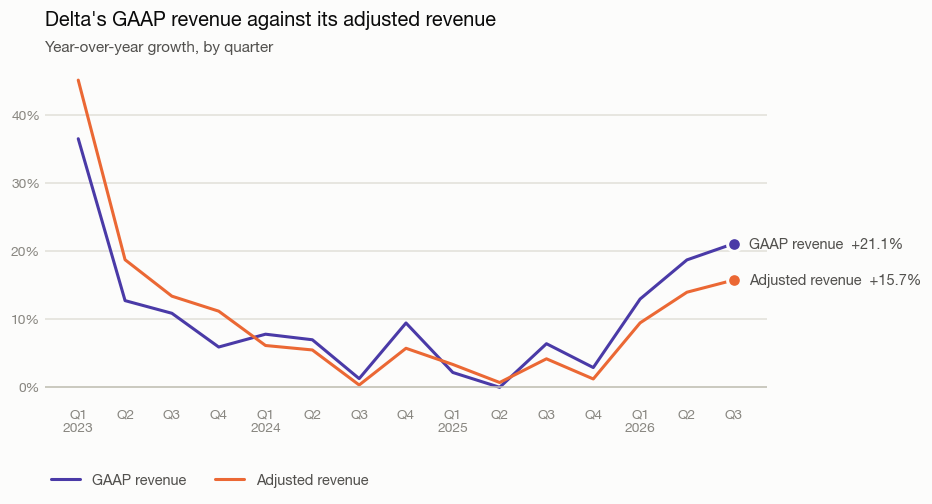

,min,max
quarter,,
2023,-8.6,-2.5
2024,0.9,3.7
2025,-1.2,2.2
2026,3.5,5.4


In [12]:
chart = table.loc["2023Q1":, ["gaap_revenue_yoy_pct", "adj_revenue_yoy_pct"]]
chart.columns = ["GAAP revenue", "Adjusted revenue"]
line_chart(chart, "Delta's GAAP revenue against its adjusted revenue", "Year-over-year growth, by quarter")
plt.show()

refinery_effect = (chart["GAAP revenue"] - chart["Adjusted revenue"]).rename("GAAP growth minus adjusted growth, in points")
refinery_effect.groupby(refinery_effect.index.year).agg(["min", "max"]).round(1)

**What it shows.** The gap between the two lines is the refinery, and it cuts both ways. In 2023, GAAP revenue grew *less* than adjusted revenue, by 2.5 to 8.6 points, because the refinery's outside sales were lower than in 2022. In 2026 it grew *more*, by 3.5 to 5.4 points, as refinery sales rose. Someone tracking GAAP revenue would have credited or blamed flying for swings that came from selling fuel. That is why this analysis uses adjusted revenue.

### Chart 3: Delta's yield against the airfare index

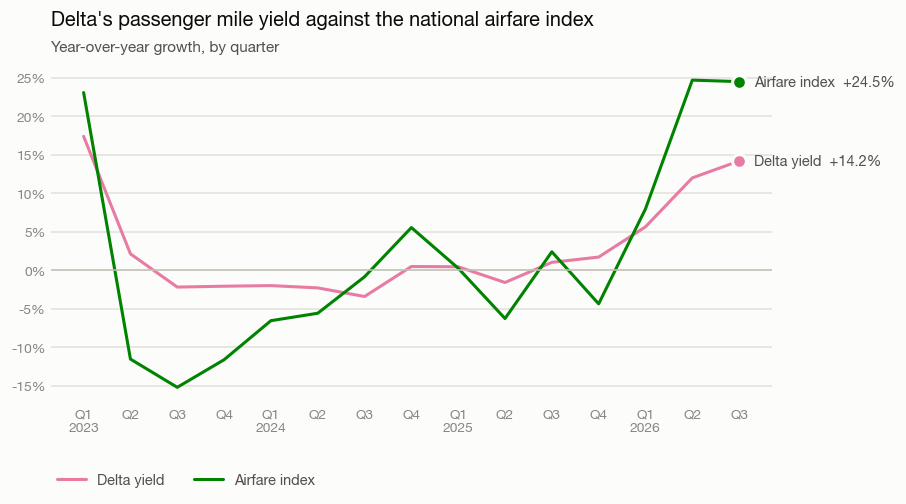

Correlation: 0.90
Same direction in 13 of 15 quarters
Typical swing (standard deviation): Delta yield 6.6 points, airfare index 13.2 points


In [13]:
chart = table.loc["2023Q1":, ["yield_yoy_pct", "airfare_yoy_pct"]]
chart.columns = ["Delta yield", "Airfare index"]
line_chart(chart, "Delta's passenger mile yield against the national airfare index", "Year-over-year growth, by quarter")
plt.show()

same_direction = (chart["Delta yield"] * chart["Airfare index"] > 0).sum()
print(f"Correlation: {chart['Delta yield'].corr(chart['Airfare index']):.2f}")
print(f"Same direction in {same_direction} of {len(chart)} quarters")
print(f"Typical swing (standard deviation): Delta yield {chart['Delta yield'].std():.1f} points, airfare index {chart['Airfare index'].std():.1f} points")

**What it shows.** Delta's yield is the average price it collects for flying one passenger one mile. The airfare index tracks ticket prices across all U.S. airlines. The two move in the same direction in 13 of 15 quarters (correlation 0.90), but the index swings about twice as hard. Through 2023 and 2024 the index fell by as much as 15% while Delta's yield slipped only 2% to 3%. In 2026 both rose: the index by about 24% in Q2 and Q3, Delta's yield by 12% and 14%.

So the index is a good signal of the *direction* of Delta's prices, but it overstates the *size*. It will need scaling down before it is used in the nowcast.

### Chart 4: Delta's fuel price

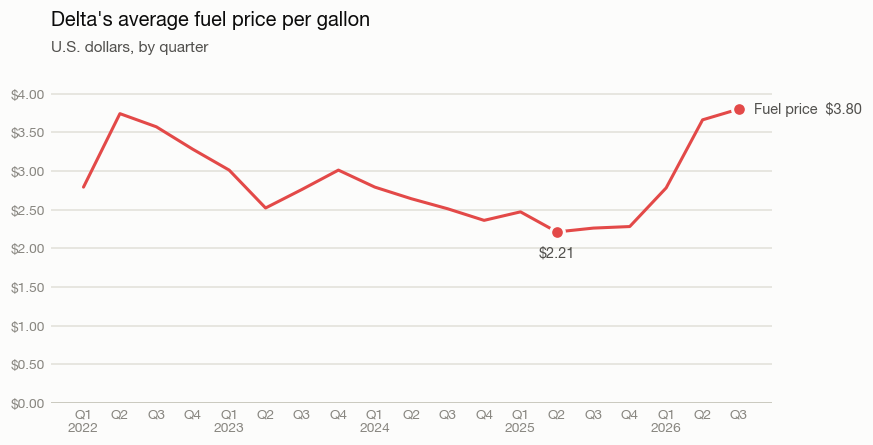

Latest quarter against a year earlier: $3.80 against $2.26, +68%


In [14]:
chart = table[["fuel_price_per_gallon_usd"]].rename(columns={"fuel_price_per_gallon_usd": "Fuel price"})
ax = line_chart(
    chart,
    "Delta's average fuel price per gallon",
    "U.S. dollars, by quarter",
    value_format="${:.2f}",
    tick_format="${:.2f}",
    from_zero=True,
)

# Mark the low point as well as the latest quarter.
low = chart["Fuel price"].idxmin()
position = list(chart.index).index(low)
ax.plot(position, chart.loc[low, "Fuel price"], "o", color=COLORS["Fuel price"], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(
    f"${chart.loc[low, 'Fuel price']:.2f}",
    (position, chart.loc[low, "Fuel price"]),
    xytext=(0, -16),
    textcoords="offset points",
    ha="center",
    fontsize=9.5,
    color=INK_SECONDARY,
)
plt.show()

latest, year_ago = chart["Fuel price"].iloc[-1], chart["Fuel price"].iloc[-5]
print(f"Latest quarter against a year earlier: ${latest:.2f} against ${year_ago:.2f}, {(latest / year_ago - 1) * 100:+.0f}%")

**What it shows.** Delta's fuel price peaked at $3.74 a gallon in Q2 2022, drifted down to $2.21 by Q2 2025, then climbed to $3.80 in Q3 2026. That is 68% higher than a year earlier and above the 2022 peak.

The rise lines up in time with the 2026 jump in Delta's yield (chart 3) and in refinery sales (chart 2). This chart shows the timing fits. Whether higher fuel costs *caused* the fare increases is taken up in the next section.